# Belfast House Price Analysis & Prediction

An end-to-end data science project analysing Belfast residential property sales data and building a machine learning model to predict property prices.

## Project Overview

This project explores historical Belfast property sales data, performs data cleaning and exploratory data analysis, and trains a Linear Regression model to predict sale prices.

The model is evaluated using RMSE, MAE and R².

## Section 1: Importing Libraries and Loading Data

First, we import all required libraries and load the Belfast sales dataset.


In [ ]:
# Required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import joblib
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("=" * 80)
print("SUCCESSFULLY RAN")
print("=" * 80)

SUCCESSFULLY RAN


In [2]:
# Load dataset from CSV
# This cell reads the CSV into a pandas DataFrame and prints high-level info

# Load the dataset
df = pd.read_csv('belfast_all-sales.csv')

print("=" * 80)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 80)

# Display basic information
print("\nDataset Shape:")
print(f"   Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\nFirst 5 rows of the dataset:")
print(df.head())

print("\nData Types:")
print(df.dtypes)

print("\nColumn Names:")
print(df.columns.tolist())

DATASET LOADED SUCCESSFULLY

Dataset Shape:
   Rows: 20, Columns: 10

First 5 rows of the dataset:
  District  SaleYr       Type  LGD_VerifiedSales  Reporting_MinPrice  \
0  BELFAST    2005  All Sales               5837               20000   
1  BELFAST    2006  All Sales               8337               24730   
2  BELFAST    2007  All Sales               6063               21543   
3  BELFAST    2008  All Sales               2277               20000   
4  BELFAST    2009  All Sales               2401               27500   

   Reporting_LQPrice  Reporting_MedianPrice  Reporting_MeanPrice  \
0              80000                 110000               127821   
1             104000                 137000               159746   
2             146000                 186000               222184   
3             118000                 157550               188774   
4              95750                 130500               149914   

   Reporting_UQPrice  Reporting_MaxPrice  
0             14

## Section 2: Exploratory Data Analysis (EDA)

This section performs comprehensive exploratory analysis including summary statistics, missing values, correlations, and visualizations.


In [3]:
# 2.1 Summary statistics for numerical columns and DataFrame info
print("=" * 80)
print("2.1 SUMMARY STATISTICS")
print("=" * 80)

print("\nDescriptive Statistics for Numerical Columns:")
print(df.describe())

print("\nData Info:")
print(df.info())

2.1 SUMMARY STATISTICS

Descriptive Statistics for Numerical Columns:
           SaleYr  LGD_VerifiedSales  Reporting_MinPrice  Reporting_LQPrice  \
count    20.00000          20.000000            20.00000          20.000000   
mean   2014.50000        4399.100000         28761.15000       92482.500000   
std       5.91608        1499.247211          8846.94792       22350.216501   
min    2005.00000        2277.000000         20000.00000       60000.000000   
25%    2009.75000        3427.250000         20750.00000       78750.000000   
50%    2014.50000        4547.500000         26750.00000       89250.000000   
75%    2019.25000        4797.750000         35750.00000      106000.000000   
max    2024.00000        8337.000000         48000.00000      146000.000000   

       Reporting_MedianPrice  Reporting_MeanPrice  Reporting_UQPrice  \
count              20.000000            20.000000          20.000000   
mean           128305.800000        154332.400000      179528.750000   
st

In [4]:
# 2.2 Missing value analysis
print("\n" + "=" * 80)
print("2.2 MISSING VALUE ANALYSIS")
print("=" * 80)

missing_values = df.isnull().sum()
print("\nMissing Values per Column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found!")

print(f"\nTotal missing values in dataset: {df.isnull().sum().sum()}")


2.2 MISSING VALUE ANALYSIS

Missing Values per Column:
No missing values found!

Total missing values in dataset: 0



2.3 CORRELATION MATRIX

Numerical columns: ['SaleYr', 'LGD_VerifiedSales', 'Reporting_MinPrice', 'Reporting_LQPrice', 'Reporting_MedianPrice', 'Reporting_MeanPrice', 'Reporting_UQPrice', 'Reporting_MaxPrice']

Correlation Matrix:
                         SaleYr  LGD_VerifiedSales  Reporting_MinPrice  \
SaleYr                 1.000000           0.018526            0.805924   
LGD_VerifiedSales      0.018526           1.000000            0.133011   
Reporting_MinPrice     0.805924           0.133011            1.000000   
Reporting_LQPrice      0.129016           0.331924            0.347445   
Reporting_MedianPrice  0.178587           0.292275            0.396690   
Reporting_MeanPrice    0.242241           0.283340            0.412995   
Reporting_UQPrice      0.276882           0.279922            0.444773   
Reporting_MaxPrice    -0.264453           0.602681           -0.157147   

                       Reporting_LQPrice  Reporting_MedianPrice  \
SaleYr                          0.1

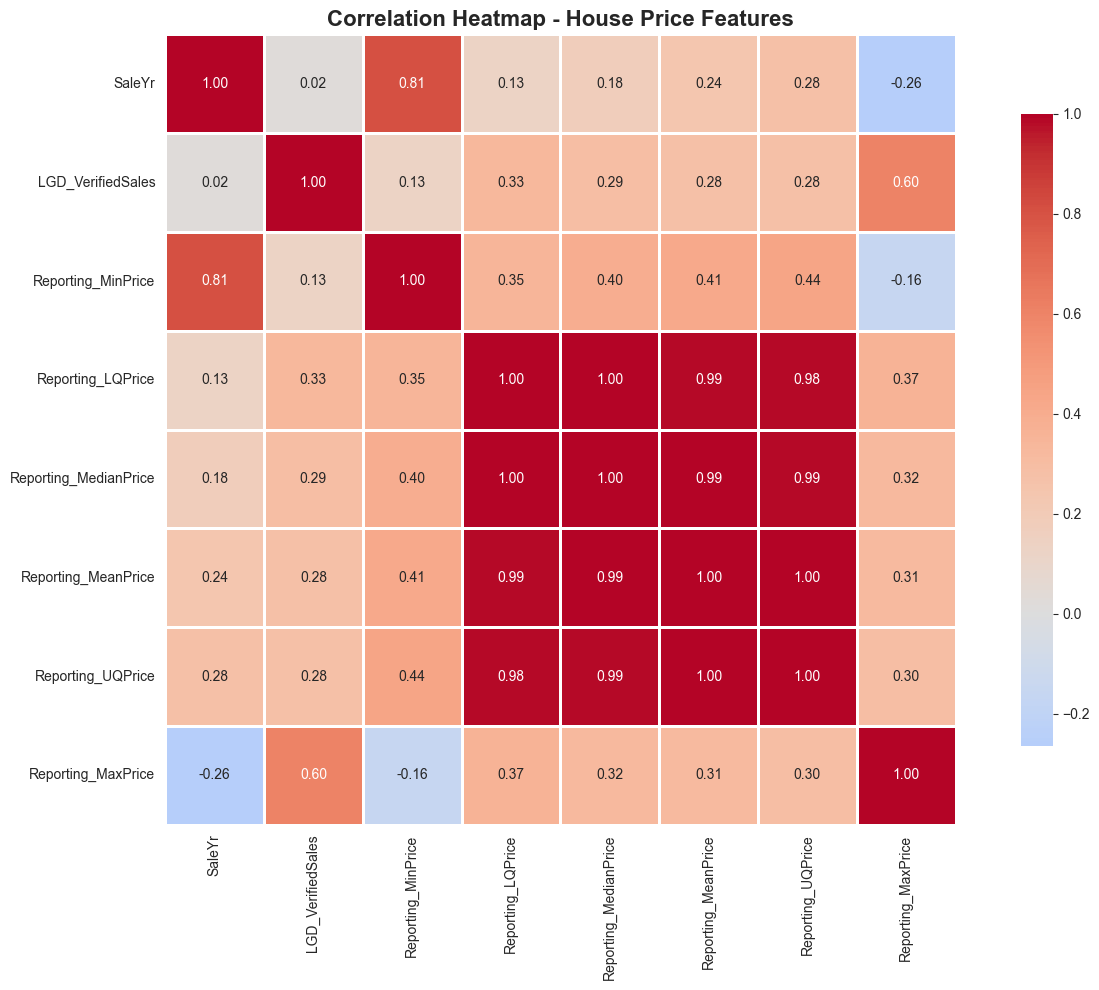

In [5]:
# 2.3 Correlation analysis and heatmap
print("\n" + "=" * 80)
print("2.3 CORRELATION MATRIX")
print("=" * 80)

# Select only numerical columns for correlation
numerical_cols = df.select_dtypes(include=[np.number]).columns
print(f"\nNumerical columns: {numerical_cols.tolist()}")

# Calculate correlation matrix
correlation_matrix = df[numerical_cols].corr()
print("\nCorrelation Matrix:")
print(correlation_matrix)

# Create a correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap - House Price Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


2.4 DISTRIBUTION OF KEY NUMERICAL FEATURES


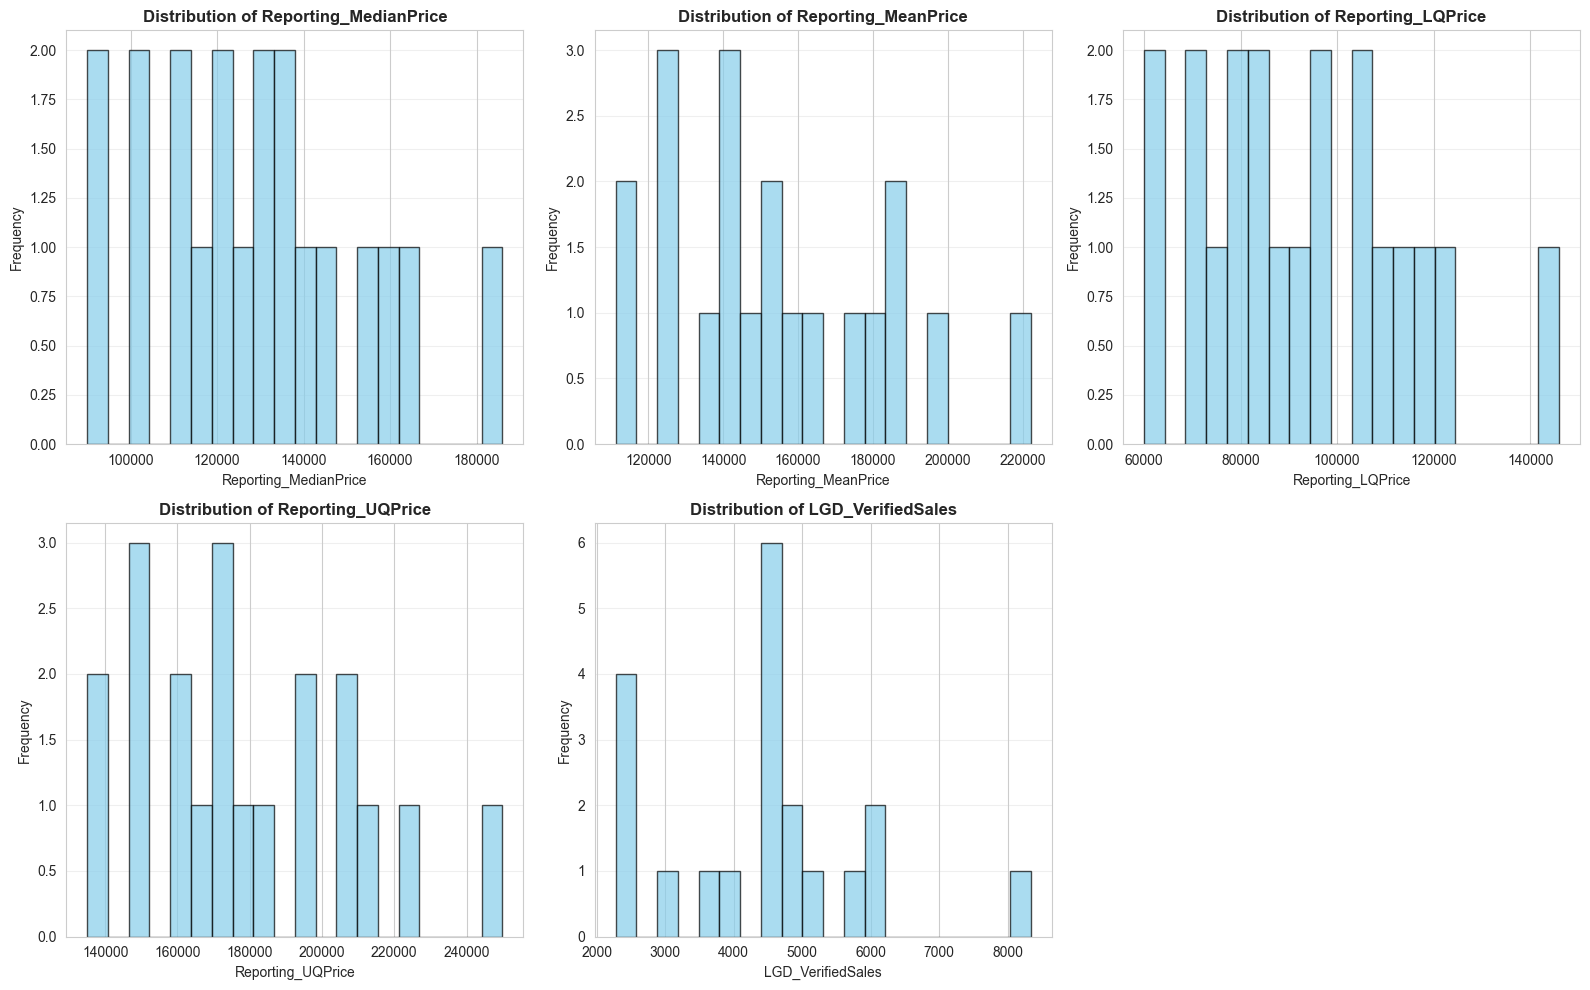

In [6]:
# 2.4 Distribution of Key Numerical Features
print("\n" + "=" * 80)
print("2.4 DISTRIBUTION OF KEY NUMERICAL FEATURES")
print("=" * 80)

# Select key numerical features
key_features = ['Reporting_MedianPrice', 'Reporting_MeanPrice', 
                'Reporting_LQPrice', 'Reporting_UQPrice', 'LGD_VerifiedSales']

# Create histograms for key features
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, feature in enumerate(key_features):
    axes[idx].hist(df[feature], bins=20, color='skyblue', edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'Distribution of {feature}', fontweight='bold')
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel('Frequency')
    axes[idx].grid(axis='y', alpha=0.3)

# Hide the last empty subplot
axes[-1].axis('off')

plt.tight_layout()
plt.show()


2.5 BOXPLOTS FOR OUTLIER DETECTION


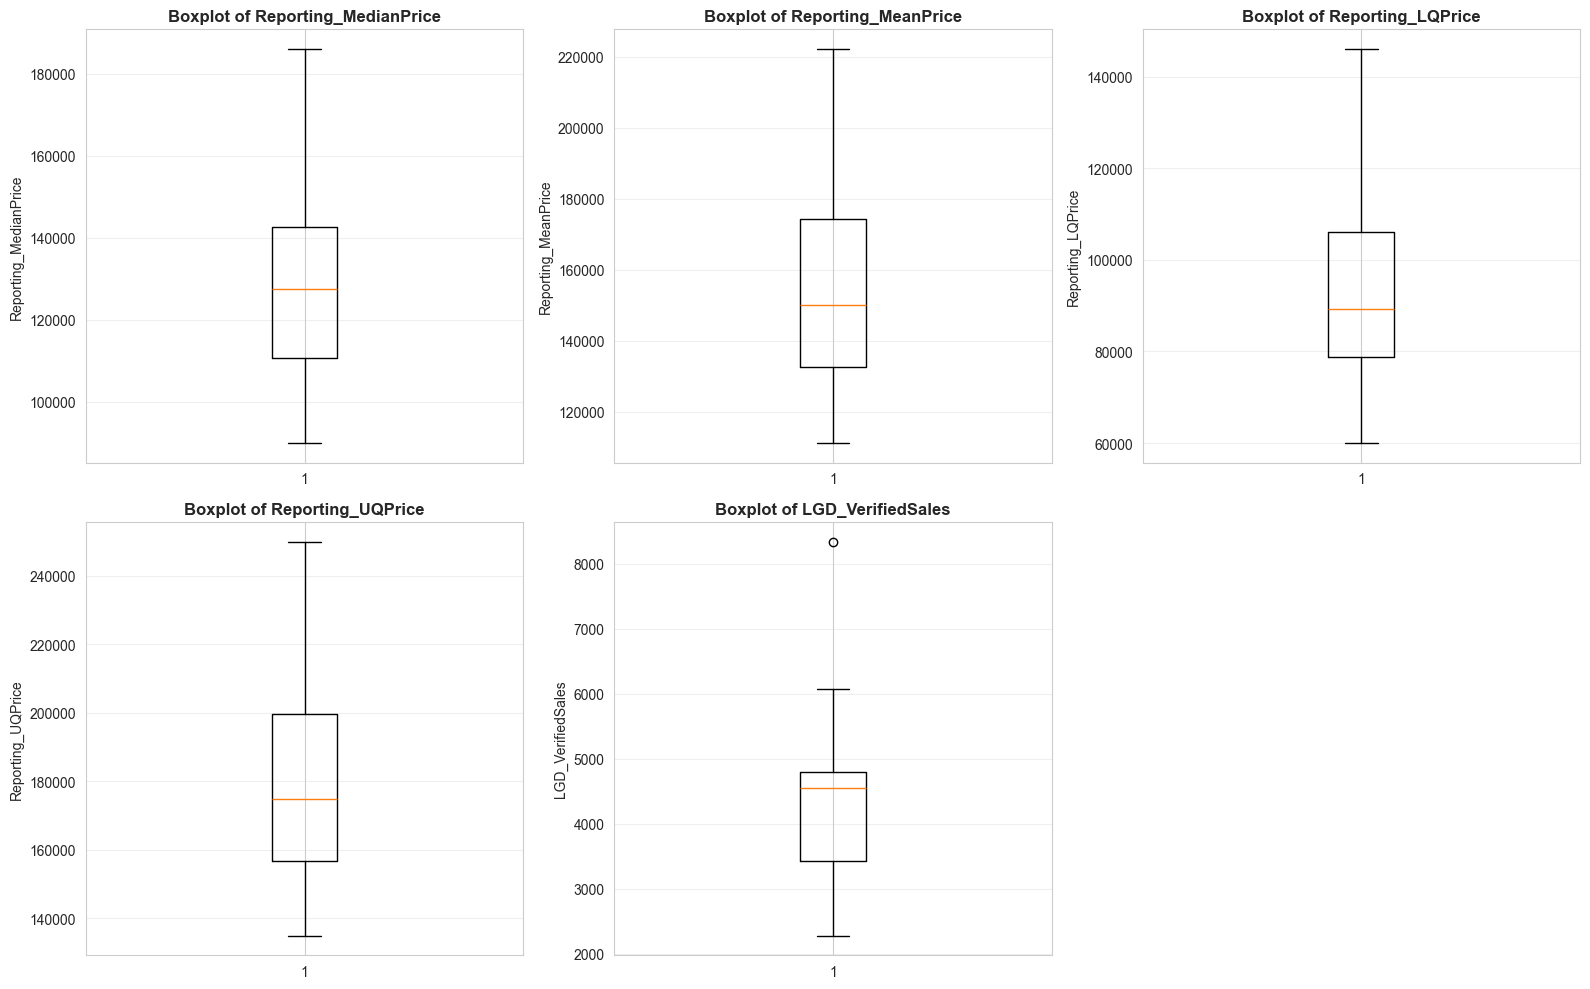

In [7]:
# 2.5 Boxplots for Outlier Detection
print("\n" + "=" * 80)
print("2.5 BOXPLOTS FOR OUTLIER DETECTION")
print("=" * 80)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, feature in enumerate(key_features):
    axes[idx].boxplot(df[feature], vert=True)
    axes[idx].set_title(f'Boxplot of {feature}', fontweight='bold')
    axes[idx].set_ylabel(feature)
    axes[idx].grid(axis='y', alpha=0.3)

# Hide the last empty subplot
axes[-1].axis('off')

plt.tight_layout()
plt.show()


2.6 MEDIAN PRICE TREND OVER TIME


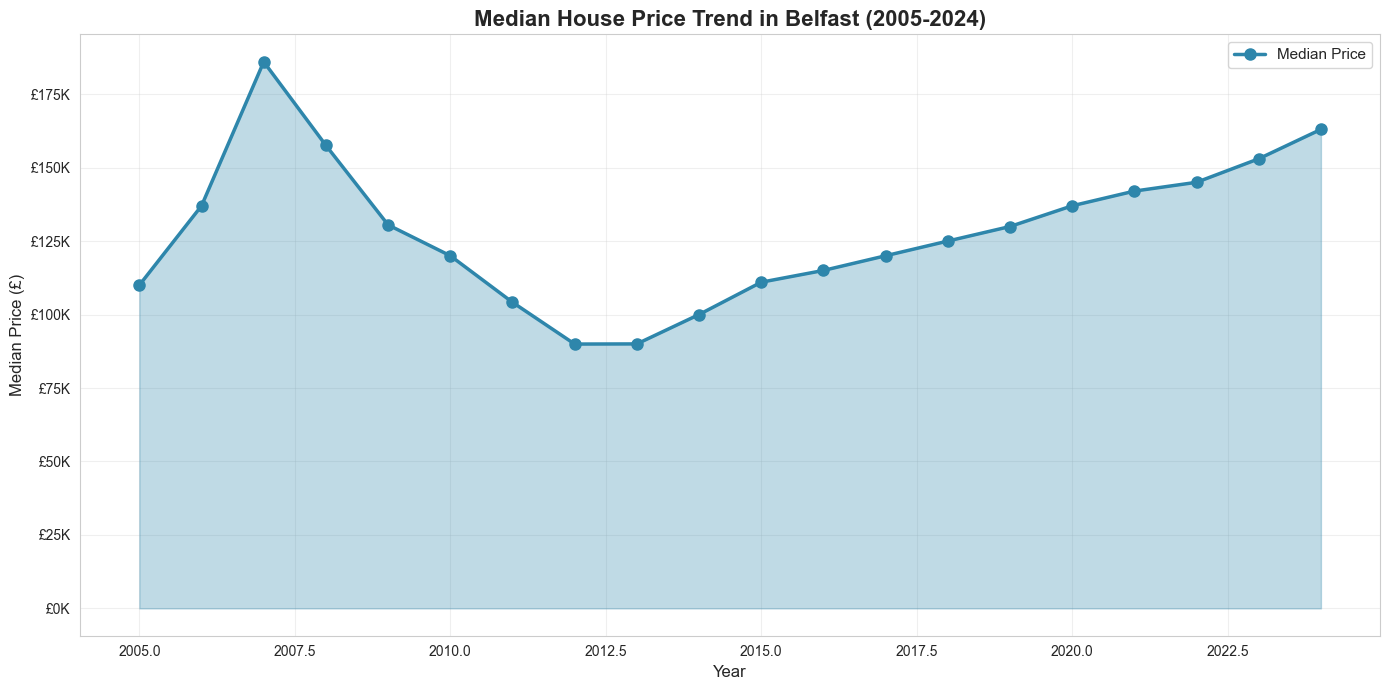

In [8]:
# 2.6 Median Price Trend Over Time
# Plot the median house price across years to view trends
print("\n" + "=" * 80)
print("2.6 MEDIAN PRICE TREND OVER TIME")
print("=" * 80)

plt.figure(figsize=(14, 7))
plt.plot(df['SaleYr'], df['Reporting_MedianPrice'], marker='o', linewidth=2.5, 
         markersize=8, color='#2E86AB', label='Median Price')
plt.fill_between(df['SaleYr'], df['Reporting_MedianPrice'], alpha=0.3, color='#2E86AB')

plt.title('Median House Price Trend in Belfast (2005-2024)', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Median Price (£)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)

# Format y-axis as currency
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{x/1000:.0f}K'))

plt.tight_layout()
plt.show()

## Section 3: Data Cleaning and Preparation

This section handles missing values, encodes categorical features, removes outliers, and prepares the data for modeling.


In [9]:
# 3.1 Create a working copy and handle missing values
# Create a copy to avoid modifying the original raw data.
print("=" * 80)
print("3.1 DATA PREPARATION - CREATING WORKING COPY")
print("=" * 80)

# Work on a copy of the data to keep raw data intact
df_processed = df.copy()
print(f"Working copy created. Shape: {df_processed.shape}")


# 3.2 Handle Missing Values
print("\n" + "=" * 80)
print("3.2 HANDLING MISSING VALUES")
print("=" * 80)

# Check for missing values and impute numeric columns with column mean where necessary
missing_count = df_processed.isnull().sum().sum()
if missing_count > 0:
    print(f"Found {missing_count} missing values")
    print("Filling missing values with column mean...")
    df_processed = df_processed.fillna(df_processed.mean(numeric_only=True))
else:
    print("No missing values found")

3.1 DATA PREPARATION - CREATING WORKING COPY
Working copy created. Shape: (20, 10)

3.2 HANDLING MISSING VALUES
No missing values found


In [10]:
# 3.3 Encode Categorical Features
# Identify object-type columns and encode them for modelling
print("\n" + "=" * 80)
print("3.3 ENCODING CATEGORICAL FEATURES")
print("=" * 80)

# Identify categorical columns
categorical_cols = df_processed.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical columns found: {categorical_cols}")

# Use Label Encoding for categorical variables
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_processed[col] = le.fit_transform(df_processed[col].astype(str))
    label_encoders[col] = le
    print(f"Encoded '{col}': {len(le.classes_)} unique categories")


3.3 ENCODING CATEGORICAL FEATURES

Categorical columns found: ['District', 'Type']
Encoded 'District': 1 unique categories
Encoded 'Type': 1 unique categories


In [11]:
# 3.4 Outlier Detection and Handling (IQR Method)

print("\n" + "=" * 80)
print("3.4 OUTLIER DETECTION AND HANDLING")
print("=" * 80)

def remove_outliers_iqr(data, columns):
    """Remove outliers using IQR method"""
    df_clean = data.copy()
    outliers_removed = 0
    
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        initial_count = len(df_clean)
        df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        removed = initial_count - len(df_clean)
        
        if removed > 0:
            print(f"  {col}: Removed {removed} outliers")
            outliers_removed += removed
    
    return df_clean, outliers_removed

# Select price columns for outlier removal
price_columns = ['Reporting_MinPrice', 'Reporting_LQPrice', 'Reporting_MedianPrice', 
                 'Reporting_MeanPrice', 'Reporting_UQPrice', 'Reporting_MaxPrice']

print(f"\nDataset shape before outlier removal: {df_processed.shape}")
df_processed, outliers_count = remove_outliers_iqr(df_processed, price_columns)
print(f"Dataset shape after outlier removal: {df_processed.shape}")
print(f"Total outliers removed: {outliers_count}")


3.4 OUTLIER DETECTION AND HANDLING

Dataset shape before outlier removal: (20, 10)
  Reporting_MaxPrice: Removed 1 outliers
Dataset shape after outlier removal: (19, 10)
Total outliers removed: 1


In [12]:
# 3.5 Feature Selection and Preparation
# Define the modelling target and choose feature columns.
print("\n" + "=" * 80)
print("3.5 FEATURE SELECTION AND TARGET VARIABLE")
print("=" * 80)

# Define target variable
target_column = 'Reporting_MedianPrice'

# Select features for the model
# Exclude District as it adds limited value; keep SaleYr and LGD_VerifiedSales
feature_columns = [col for col in df_processed.columns 
                   if col != target_column and col != 'District']

print(f"\nTarget Variable: {target_column}")
print(f"Feature Columns ({len(feature_columns)}): {feature_columns}")

# Prepare X (features) and y (target)
X = df_processed[feature_columns].copy()
y = df_processed[target_column].copy()

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")


3.5 FEATURE SELECTION AND TARGET VARIABLE

Target Variable: Reporting_MedianPrice
Feature Columns (8): ['SaleYr', 'Type', 'LGD_VerifiedSales', 'Reporting_MinPrice', 'Reporting_LQPrice', 'Reporting_MeanPrice', 'Reporting_UQPrice', 'Reporting_MaxPrice']

Features shape: (19, 8)
Target shape: (19,)


In [13]:
# 3.6 Train-Test Split (Time-based)
# Use the most recent year as the test set to avoid look-ahead bias in forecasting.
print("\n" + "=" * 80)
print("3.6 TRAIN-TEST SPLIT (TIME-BASED)")
print("=" * 80)

# Prefer time-based split to avoid look-ahead bias. Use the most recent year as the test set.
if 'SaleYr' in X.columns:
    max_year = int(X['SaleYr'].max())
    print(f"Detected years from {int(X['SaleYr'].min())} to {max_year}")
    
    # Test on the most recent year; train on all earlier years
    train_mask = X['SaleYr'] < max_year
    test_mask = X['SaleYr'] == max_year
    X_train = X[train_mask].copy()
    X_test = X[test_mask].copy()
    y_train = y[train_mask].copy()
    y_test = y[test_mask].copy()
    print(f"Using {max_year} as test year. Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")
    if X_test.shape[0] == 0:
        print('Warning: No samples in test year; falling back to a random 80/20 split')
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
else:
    print('Column "SaleYr" not found. Falling back to random 80/20 split.')
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining set size: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Testing set size: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")


3.6 TRAIN-TEST SPLIT (TIME-BASED)
Detected years from 2005 to 2024
Using 2024 as test year. Train samples: 18, Test samples: 1

Training set size: 18 samples (94.7%)
Testing set size: 1 samples (5.3%)


In [14]:
# 3.7 Feature Scaling (StandardScaler)
print("\n" + "=" * 80)
print("3.7 FEATURE SCALING (STANDARDSCALER)")
print("=" * 80)

# Initialize and fit the scaler on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for easier handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_columns, index=X_test.index)

print("\nFeature scaling complete!")
print(f"Training set (scaled) shape: {X_train_scaled.shape}")
print(f"Testing set (scaled) shape: {X_test_scaled.shape}")
print(f"\nSample scaled values (first 3 rows):")
print(X_train_scaled.head(3))


3.7 FEATURE SCALING (STANDARDSCALER)

Feature scaling complete!
Training set (scaled) shape: (18, 8)
Testing set (scaled) shape: (1, 8)

Sample scaled values (first 3 rows):
     SaleYr  Type  LGD_VerifiedSales  Reporting_MinPrice  Reporting_LQPrice  \
0 -1.787593   0.0           1.379366           -1.018284          -0.472476   
2 -1.409044   0.0           1.566539           -0.819805           2.583890   
3 -1.219769   0.0          -1.569023           -1.018284           1.287250   

   Reporting_MeanPrice  Reporting_UQPrice  Reporting_MaxPrice  
0            -0.830480          -0.993094            0.812797  
2             2.460950           2.491402            1.725440  
3             1.295592           1.030601            1.163814  


## Section 4: Model Development

Build and evaluate a Linear Regression baseline (simple and transparent).

In [15]:
# 4.1 Linear Regression Model
print('=' * 80)
print('4.1 LINEAR REGRESSION MODEL')
print('=' * 80)

# Create the model and fit it
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

# Basic metrics
rmse_train_lr = np.sqrt(mean_squared_error(y_train, y_train_pred_lr))
rmse_test_lr = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))
mae_train_lr = mean_absolute_error(y_train, y_train_pred_lr)
mae_test_lr = mean_absolute_error(y_test, y_test_pred_lr)
r2_train_lr = r2_score(y_train, y_train_pred_lr)
r2_test_lr = r2_score(y_test, y_test_pred_lr)

# Print results
print('\nLINEAR REGRESSION - Results (rounded)')
print(f'  Train RMSE: £{rmse_train_lr:,.2f}')
print(f'  Test  RMSE: £{rmse_test_lr:,.2f}')
print(f'  Train MAE : £{mae_train_lr:,.2f}')
print(f'  Test  MAE : £{mae_test_lr:,.2f}')
print(f'  Train R2  : {r2_train_lr:.3f}')
print(f'  Test  R2  : {r2_test_lr:.3f}')

# Store results for later
lr_results = {
    'Model': 'Linear Regression',
    'Train_RMSE': rmse_train_lr,
    'Test_RMSE': rmse_test_lr,
    'Train_MAE': mae_train_lr,
    'Test_MAE': mae_test_lr,
    'Train_R2': r2_train_lr,
    'Test_R2': r2_test_lr,
    'Model_Object': lr_model
}

print('\nLinear Regression done')

# 4.1b Simple log-target try
print('\nTrying linear regression on log(target) to see if error improves')
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

lr_model_log = LinearRegression()
lr_model_log.fit(X_train_scaled, y_train_log)
y_test_pred_lr_log = lr_model_log.predict(X_test_scaled)

# Inverse transform predictions and compute metrics
y_test_pred_lr_log_inv = np.expm1(y_test_pred_lr_log)
rmse_test_lr_log = np.sqrt(mean_squared_error(y_test, y_test_pred_lr_log_inv))
mae_test_lr_log = mean_absolute_error(y_test, y_test_pred_lr_log_inv)
r2_test_lr_log = r2_score(y_test, y_test_pred_lr_log_inv)

print('\nLINEAR REGRESSION (log-target) - Test Results (rounded)')
print(f'  Test RMSE (inv): £{rmse_test_lr_log:,.2f}')
print(f'  Test MAE  (inv): £{mae_test_lr_log:,.2f}')
print(f'  Test R2        : {r2_test_lr_log:.3f}')

lr_results_log = {
    'Model': 'Linear Regression (log-target)',
    'Test_RMSE': rmse_test_lr_log,
    'Test_MAE': mae_test_lr_log,
    'Test_R2': r2_test_lr_log,
    'Model_Object': lr_model_log
}

4.1 LINEAR REGRESSION MODEL

LINEAR REGRESSION - Results (rounded)
  Train RMSE: £1,363.17
  Test  RMSE: £632.09
  Train MAE : £1,090.83
  Test  MAE : £632.09
  Train R2  : 0.997
  Test  R2  : nan

Linear Regression done

Trying linear regression on log(target) to see if error improves

LINEAR REGRESSION (log-target) - Test Results (rounded)
  Test RMSE (inv): £4,627.52
  Test MAE  (inv): £4,627.52
  Test R2        : nan


In [16]:
# 4.2 Model Comparison Table
# Summarise the Linear Regression results
print('\n' + '=' * 80)
print('4.2 MODEL COMPARISON SUMMARY')
print('=' * 80)

# Create a simple comparison dataframe
comparison_data = [
    {
        'Model': 'Linear Regression',
        'Test RMSE': f"£{rmse_test_lr:,.2f}",
        'Test MAE': f"£{mae_test_lr:,.2f}",
        'Test R2': f"{r2_test_lr:.4f}"
    },
    {
        'Model': 'Linear Regression (log-target)',
        'Test RMSE': f"£{lr_results_log['Test_RMSE']:,.2f}",
        'Test MAE': f"£{lr_results_log['Test_MAE']:,.2f}",
        'Test R2': f"{lr_results_log['Test_R2']:.4f}"
    }
]

comparison_df = pd.DataFrame(comparison_data)
print('\n' + comparison_df.to_string(index=False))

# Select best LR variant by Test R2
results_list = [lr_results, lr_results_log]
best_model_idx = np.argmax([r['Test_R2'] for r in results_list])
best_model_name = results_list[best_model_idx]['Model']
best_model_obj = results_list[best_model_idx]['Model_Object']

print('\n' + '=' * 80)
print(f'BEST MODEL: {best_model_name}')
print(f"   Test R2 Score: {results_list[best_model_idx]['Test_R2']:.4f}")
print('=' * 80)


4.2 MODEL COMPARISON SUMMARY

                         Model Test RMSE  Test MAE Test R2
             Linear Regression   £632.09   £632.09     nan
Linear Regression (log-target) £4,627.52 £4,627.52     nan

BEST MODEL: Linear Regression
   Test R2 Score: nan


## Section 5: Model Evaluation & Visualisation

Generate comprehensive visualizations including actual vs predicted plots, feature importance, and performance comparisons.


5.1 ACTUAL VS PREDICTED VALUES VISUALIZATION


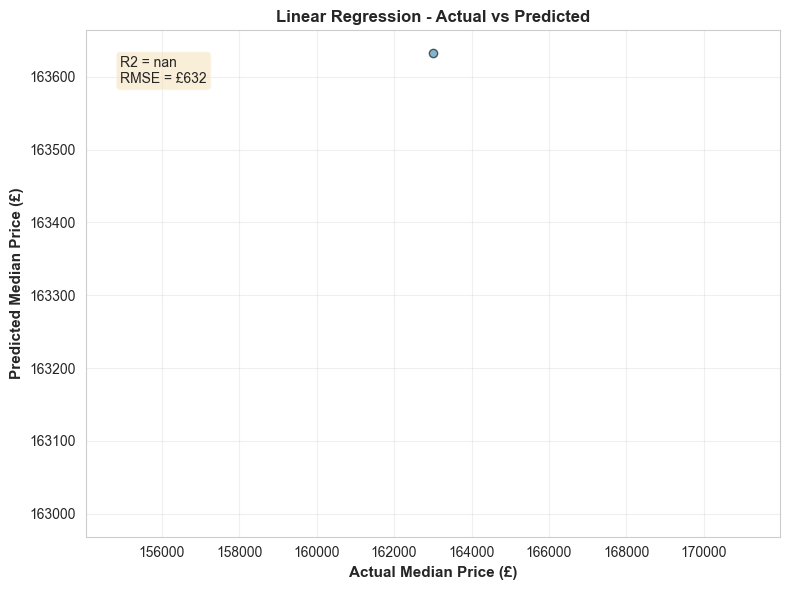


Actual vs Predicted visualization complete!


In [17]:
# 5.1 Actual vs Predicted Values - Linear Regression
print('=' * 80)
print('5.1 ACTUAL VS PREDICTED VALUES VISUALIZATION')
print('=' * 80)

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_test_pred_lr, alpha=0.6, color='#2E86AB', edgecolor='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Median Price (£)', fontsize=11, fontweight='bold')
plt.ylabel('Predicted Median Price (£)', fontsize=11, fontweight='bold')
plt.title('Linear Regression - Actual vs Predicted', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.text(0.05, 0.95, f"R2 = {r2_test_lr:.4f}\nRMSE = £{rmse_test_lr:,.0f}", transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
plt.tight_layout()
plt.show()

print('\nActual vs Predicted visualization complete!')

**Section 5 — How to read these results**

Actual vs Predicted scatter plot

The actual vs predicted scatter plot shows how close the model’s predictions are to the real median house prices. Each point represents one value from the test set, with the diagonal line showing where predictions would be perfect. Points close to the line mean the model is performing well, while points above or below it show under- or over-prediction. If the points spread out more at higher prices, it suggests the model is less accurate for more expensive properties.

Model performance is measured using RMSE, MAE and R2. RMSE and MAE show the average size of the prediction errors in pounds, with RMSE giving more weight to larger mistakes. R2 shows how well the model explains changes in house prices, with higher values meaning a better fit. These metrics are used together to compare models and decide which one performs best on the test data.